In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
from tqdm.auto import tqdm
from dask.diagnostics import ProgressBar
import cartopy.feature as cfeature
import xesmf
import dask
import glob
import os
import seaborn as sns
import pandas as pd
import geopandas as gpd
from dask_jobqueue import PBSCluster
from dask.distributed import Client
import matplotlib as mpl
import matplotlib.gridspec as gridspec
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
era5_msl = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/MSL-ERA5.trend.1950-2024.May.Roll30.nc')
cesm_msl = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/PSL.trend.1950-2024.May.Roll30.nc')
cesm_msl_rg = xesmf.Regridder(cesm_msl,era5_msl,method='bilinear')(cesm_msl)
var = list(cesm_msl_rg.data_vars)[0]
obs = era5_msl['polyfit_coefficients']

ds_sig = ((obs >= cesm_msl_rg[var].min('lemem')) & (obs <= cesm_msl_rg[var].max('lemem')))

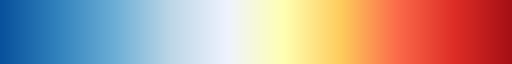

In [3]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#08519c', '#3182bd', '#6baed6', '#bdd7e7', '#eff3ff','#ffffb2','#fecc5c','#fb6a4a','#de2d26','#a50f15']
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(256,combined_colors)
cmap1

In [4]:
def plot_simulated(llon, llat, prec, row, col, levs, cmap1, shape_feature, ds_sig, ax1):
    g = ax1.gridlines(draw_labels=True, ylocs=np.arange(-10, 80, 10),xlocs=np.arange(20, 140, 15))
    g.bottom_labels = row == 0
    g.left_labels = col == 0
    g.top_labels = g.right_labels = False
    g.xlines = g.ylines = False
    g.xlabel_style = g.ylabel_style = {'size': 7.5, 'color': 'k'}
    pc1 = ax1.contourf(llon, llat, prec, cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')
    ax1.add_geometries(shape_feature.geometry, crs=ccrs.PlateCarree(),facecolor='none', edgecolor='k', linewidth=0.5)
    plt.rcParams['hatch.linewidth'] = 0.4
    cs = ax1.contourf(ds_sig.longitude, ds_sig.latitude, ds_sig.astype(int),levels=[0.5, 1.5], colors='none', hatches=['....'],transform=ccrs.PlateCarree())
    for c in cs.collections:
        c.set_edgecolor('#1a1a1a')  # Hatch color
        c.set_linewidth(0)      # Hatch line thickness
    return pc1

/glade/derecho/scratch/adixit/tmp/ipykernel_31829/133956603.py:12: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:


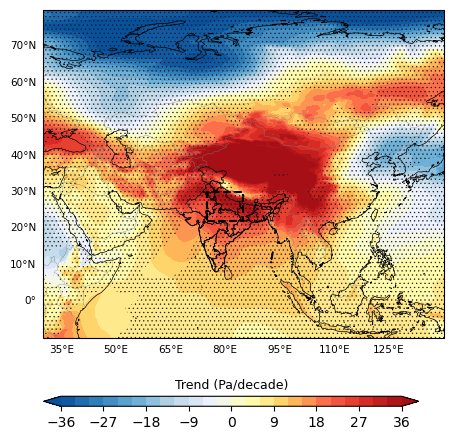

In [50]:
import matplotlib.patches as patches

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf = gpd.read_file(shp_file)

f = plt.figure(figsize=(5, 5))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.099, bottom=0.20, wspace=0.002, hspace=0.16)


levs = np.arange(-36,37,3)
c1diff = cmap1
factor = 365.2425 * 24 * 3600 * 1e9 * 10

ax1 = f.add_subplot(gs1[0, 0], projection=ccrs.PlateCarree())
ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
ax1.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor='gray')
data = obs#cesm_msl_rg['polyfit_coefficients'].mean(dim='lemem')*factor
pc = plot_simulated(data.longitude, data.latitude, data*factor, 0, 0,
                    levs, c1diff, gdf, ds_sig, ax1)

cbar_ax = f.add_axes([0.1, 0.075, 0.75, 0.02])
cb = plt.colorbar(pc, cax=cbar_ax, orientation='horizontal', extend='both')
cb.ax.set_title('Trend (Pa/decade)', fontsize=9)

ax1.spines['geo'].set_visible(True)
ax1.set_extent([30, 140, -10, 80], crs=ccrs.PlateCarree())
#ax1.set_xticks(np.arange(60, 111, 10), crs=ccrs.PlateCarree())
#ax1.set_yticks(np.arange(-10, 80, 10), crs=ccrs.PlateCarree())
ax1.tick_params(labelsize=8)

rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k',
                               facecolor='none', linewidth=1.5, linestyle='--')
ax1.add_patch(rectangle2)
plt.savefig("May-slp_verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()

In [51]:
era5_msl = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/MSL-ERA5.trend.1950-2024.June.Roll30.nc')
cesm_msl = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/PSL.trend.1950-2024.June.Roll30.nc')
cesm_msl_rg = xesmf.Regridder(cesm_msl,era5_msl,method='bilinear')(cesm_msl)
var = list(cesm_msl_rg.data_vars)[0]
obs = era5_msl['polyfit_coefficients']

ds_sig = ((obs >= cesm_msl_rg[var].min('lemem')) & (obs <= cesm_msl_rg[var].max('lemem')))

/glade/derecho/scratch/adixit/tmp/ipykernel_31829/133956603.py:12: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:


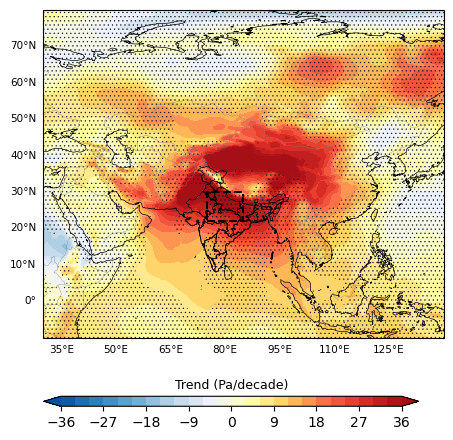

In [52]:
import matplotlib.patches as patches

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf = gpd.read_file(shp_file)

f = plt.figure(figsize=(5, 5))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.099, bottom=0.20, wspace=0.002, hspace=0.16)

levs = np.arange(-36,37,3)
c1diff = cmap1
factor = 365.2425 * 24 * 3600 * 1e9 * 10

ax1 = f.add_subplot(gs1[0, 0], projection=ccrs.PlateCarree())
ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
ax1.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor='gray')
data = obs*factor#cesm_msl_rg['polyfit_coefficients'].mean(dim='lemem')*factor
pc = plot_simulated(data.longitude, data.latitude, data, 0, 0,
                    levs, c1diff, gdf, ds_sig, ax1)

cbar_ax = f.add_axes([0.1, 0.075, 0.75, 0.02])
cb = plt.colorbar(pc, cax=cbar_ax, orientation='horizontal', extend='both')
cb.ax.set_title('Trend (Pa/decade)', fontsize=9)

ax1.spines['geo'].set_visible(True)
ax1.set_extent([30, 140, -10, 80], crs=ccrs.PlateCarree())
#ax1.set_xticks(np.arange(60, 111, 10), crs=ccrs.PlateCarree())
#ax1.set_yticks(np.arange(10, 46, 10), crs=ccrs.PlateCarree())
ax1.tick_params(labelsize=8)

rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k',
                               facecolor='none', linewidth=1.5, linestyle='--')
ax1.add_patch(rectangle2)
plt.savefig("June-slp_verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()